In [1]:
import numpy as np

In [2]:
time = np.array([0, 5, 10, 15, 20, 25, 30, 35, 40])

In [3]:
temperature = np.array([40.0, 34.2, 30.0, 27.2, 25.5, 24.1, 23.7, 23.5, 22.6])

In [4]:
import matplotlib.pyplot as plt

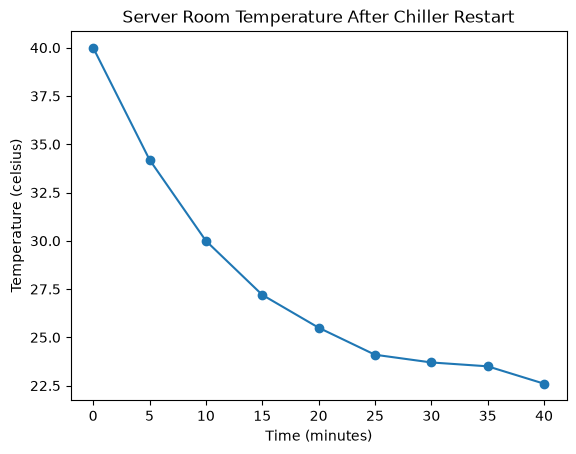

In [5]:
plt.plot(time, temperature, marker = "o", label = "Actual")
plt.title("Server Room Temperature After Chiller Restart")
plt.xlabel("Time (minutes)")
plt.ylabel("Temperature (celsius)")
plt.show()

In [6]:
temp_difference = temperature - 22
print(temp_difference)

[18.  12.2  8.   5.2  3.5  2.1  1.7  1.5  0.6]


In [7]:
log_temp_difference = np.log(temp_difference)
gradient, intercept = np.polyfit(time, log_temp_difference, 1)
print(gradient)
print(intercept)

-0.07965683306545028
2.8753450974791943


In [8]:
k = -gradient
print(k)

0.07965683306545028


In [9]:
predicted_temp = 22 + 18 * np.exp(-k * time)
print(predicted_temp)

[40.         34.08648145 30.1157241  27.44947494 25.65916543 24.45702417
 23.64982095 23.10780724 22.74386065]


In [10]:
residuals = temperature - predicted_temp
print(residuals)

[ 0.          0.11351855 -0.1157241  -0.24947494 -0.15916543 -0.35702417
  0.05017905  0.39219276 -0.14386065]


In [11]:
squared_residuals = residuals **2
print(squared_residuals)

[0.         0.01288646 0.01339207 0.06223774 0.02533363 0.12746626
 0.00251794 0.15381516 0.02069589]


In [12]:
mean_squared_error = np.mean(squared_residuals)
print(mean_squared_error)

0.04648279449394248


In [13]:
rmse = np.sqrt(mean_squared_error)
print(rmse)


0.2155986885255624


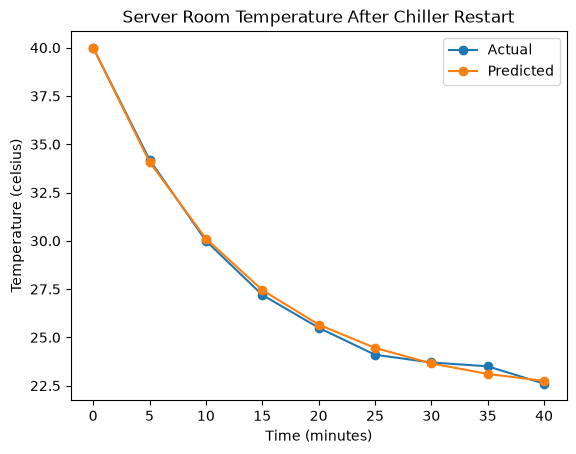

In [14]:
plt.plot(time, temperature, marker = "o", label = "Actual")
plt.plot(time, predicted_temp, marker = "o", label = "Predicted")
plt.title("Server Room Temperature After Chiller Restart")
plt.xlabel("Time (minutes)")
plt.ylabel("Temperature (celsius)")
plt.legend()
plt.show()

In [17]:
h = 1
T_euler = 40

for i in range(30):
    T_euler = T_euler - h * k * (T_euler - 22)
    
print(T_euler)

23.49199123835894


In [18]:
T_exact = 22 + 18 * np.exp(-k * 30)
print(T_exact)

23.649820948448966


In [20]:
euler_error = abs(T_euler - T_exact)
print(euler_error)

0.15782971009002722


In [24]:
def cooling_rate(T):
    return -k * (T - 22)

print(cooling_rate(40))

-1.433822995178105


In [ ]:
T_rk4 = 40

for i in range(30):
    k1 = cooling_rate(T_rk4)
    T_mid = T_rk4 + h / 2 * k1
    k2 = cooling_rate(T_mid)
    k3 = cooling_rate(T_rk4 + h / 2 * k2)
    k4 = cooling_rate(T_rk4 + h * k3)

    average_rate = (k1 + 2*k2 + 2*k3 + k4) / 6
    T_rk4 = T_rk4 + h * average_rate

print(T_rk4)

23.649822362119377


In [29]:
rk4_error = abs(T_rk4 - T_exact)
print(rk4_error)

1.4136704109546372e-06


In [30]:
current_temp = 40
minutes = 0

while current_temp >= 27:
    current_temp = current_temp - h * k * (current_temp - 22)
    minutes = minutes + 1

print(current_temp)
print(minutes)


26.769459674376193
16


In [31]:
T_at_16 = 22 + 18 * np.exp(-k * 16)
print(T_at_16)

27.032225989431023


In [32]:
T_at_17 = 22 + 18 * np.exp(-k * 17)
print(T_at_17)

26.646924466791937


In [34]:
k_lower = k * 0.8
print(k_lower)

k_higher = k * 1.2
print(k_higher)

0.06372546645236023
0.09558819967854033


In [36]:
restart_time = np.log(18 / 5) / k
print(restart_time)

restart_time_lower = np.log(18 / 5) / k_lower
print(restart_time_lower)

restart_time_higher = np.log(18 / 5) / k_higher
print(restart_time_higher)

16.080652420735596
20.100815525919494
13.40054368394633


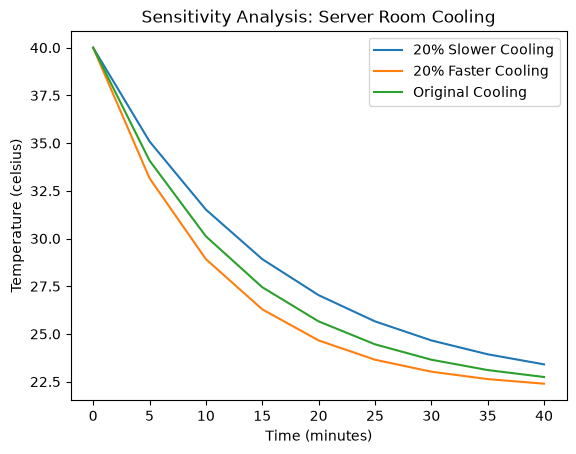

In [37]:
predicted_lower = 22 + 18 * np.exp(-k_lower * time)
predicted_higher = 22 + 18 * np.exp(-k_higher * time)

plt.plot(time, predicted_lower, label = "20% Slower Cooling")
plt.plot(time, predicted_higher, label = "20% Faster Cooling")
plt.plot(time, predicted_temp, label = "Original Cooling")
plt.title("Sensitivity Analysis: Server Room Cooling")
plt.xlabel("Time (minutes)")
plt.ylabel("Temperature (celsius)")
plt.legend()
plt.show()
